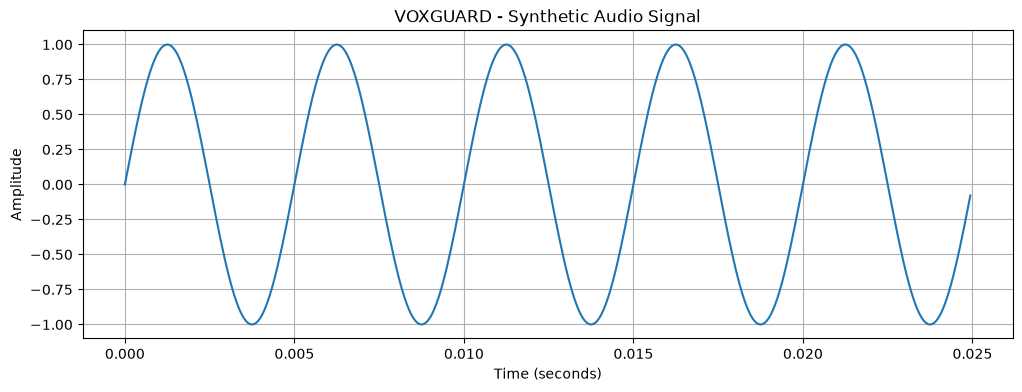

VOXGUARD - AUDIO SIGNAL INFORMATION
-----------------------------------
Sampling Rate: 16000 Hz
Duration: 1 second
Frequency: 200 Hz
Amplitude: 1
Total Samples: 16000
-----------------------------------
Audio signal generated successfully!


In [1]:

# ============================================================
# PROJECT: VOXGUARD
# PROJECT TYPE: Voice Biometric Authentication System
# VERSION: 1.0
# STAGE 1.1: Understanding Audio Signals
# ============================================================

# ------------------------------------------------------------
# 1. IMPORTING LIBRARIES
# ------------------------------------------------------------

import numpy as np
import matplotlib.pyplot as plt


# ------------------------------------------------------------
# 2. DEFINING AUDIO PARAMETERS
# ------------------------------------------------------------

# Number of samples recorded per second
sampling_rate = 16000

# Duration of the audio signal in seconds
duration = 1

# Frequency of the generated sound in Hertz
frequency = 200

# Amplitude of the sound signal
amplitude = 1


# ------------------------------------------------------------
# 3. GENERATING TIME VALUES
# ------------------------------------------------------------

time = np.arange(
    0,
    duration,
    1 / sampling_rate
)


# ------------------------------------------------------------
# 4. GENERATING SYNTHETIC AUDIO SIGNAL
# ------------------------------------------------------------

signal = amplitude * np.sin(
    2 * np.pi * frequency * time
)


# ------------------------------------------------------------
# 5. VISUALISING THE AUDIO SIGNAL
# ------------------------------------------------------------

plt.figure(figsize=(12, 4))

# Displaying the first 400 samples
plt.plot(
    time[:400],
    signal[:400]
)

plt.title("VOXGUARD - Synthetic Audio Signal")
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")

plt.grid()
plt.show()


# ------------------------------------------------------------
# 6. DISPLAYING AUDIO INFORMATION
# ------------------------------------------------------------

print("VOXGUARD - AUDIO SIGNAL INFORMATION")
print("-----------------------------------")

print("Sampling Rate:", sampling_rate, "Hz")
print("Duration:", duration, "second")
print("Frequency:", frequency, "Hz")
print("Amplitude:", amplitude)
print("Total Samples:", len(signal))

print("-----------------------------------")
print("Audio signal generated successfully!")


In [ ]:
"""
SMARTCAPTURE — One-Run Voice Intelligence Engine
GUI wizard + owner speaker verification + "capture" command + ML evaluation.

Run:
    python smartcapture_one_run.py

The app guides the user through data collection, training, evaluation and testing.
It retains the original architecture:
    Resemblyzer embeddings -> StandardScaler -> LogisticRegression
    Vosk speech recognition -> owner check + command check -> CAPTURE_EVENT

This is a course prototype, NOT secure biometric authentication.
It is vulnerable to replay attacks and may make mistakes.
Only collect recordings from people who have explicitly consented.
Never train on unverified model predictions.
"""

from __future__ import annotations

import csv
import json
import subprocess
import sys
import threading
import urllib.request
import zipfile
from datetime import datetime, timezone
from pathlib import Path

# Standard-library GUI is loaded before third-party dependencies.
import tkinter as tk
from tkinter import messagebox, simpledialog, ttk

try:
    ROOT = Path(__file__).resolve().parent
except NameError:
    # Jupyter/IPython does not always define __file__.
    ROOT = Path.cwd()
DATA = ROOT / "smartcapture_data"
TRAIN = DATA / "train"
VALID = DATA / "validation"
MODELS = ROOT / "models"
CLASSIFIER = MODELS / "owner_classifier.joblib"
META = MODELS / "metadata.json"
LOG = DATA / "runtime_log.csv"
VOSK_DIR = ROOT / "vosk-model-small-en-us-0.15"
VOSK_ZIP_URL = (
    "https://alphacephei.com/vosk/models/"
    "vosk-model-small-en-us-0.15.zip"
)
SR = 16000
REQUIRED_PACKAGES = [
    "numpy", "scipy", "sounddevice", "vosk",
    "resemblyzer", "scikit-learn", "joblib"
]

def ensure_packages():
    """Install missing Python packages into the active environment."""
    import importlib.util
    package_to_module = {
        "scikit-learn": "sklearn",
        "resemblyzer": "resemblyzer",
        "sounddevice": "sounddevice",
        "numpy": "numpy",
        "scipy": "scipy",
        "vosk": "vosk",
        "joblib": "joblib",
    }
    missing = [
        pkg for pkg, mod in package_to_module.items()
        if importlib.util.find_spec(mod) is None
    ]
    if missing:
        messagebox.showinfo(
            "SMARTCAPTURE setup",
            "Some Python packages are missing.\n\n"
            "SMARTCAPTURE will install:\n"
            + "\n".join(missing)
            + "\n\nThis requires an internet connection."
        )
        subprocess.check_call([
            sys.executable, "-m", "pip", "install", *missing
        ])


def ensure_vosk_model(status):
    """Download and extract the Vosk model if it is not already present."""
    if VOSK_DIR.exists():
        return
    zip_path = ROOT / "vosk-model-small-en-us-0.15.zip"
    status("Downloading Vosk English speech model. This may take a few minutes...")
    urllib.request.urlretrieve(VOSK_ZIP_URL, zip_path)
    status("Extracting Vosk model...")
    with zipfile.ZipFile(zip_path, "r") as archive:
        archive.extractall(ROOT)
    zip_path.unlink(missing_ok=True)
    if not VOSK_DIR.exists():
        raise RuntimeError("Vosk model extraction failed. Expected folder not found.")


def now():
    return datetime.now(timezone.utc).isoformat()


def record(seconds, prompt, save_to, status):
    """Record mono 16 kHz audio and save it as WAV."""
    import numpy as np
    import sounddevice as sd
    from scipy.io import wavfile

    messagebox.showinfo(
        "Voice recording",
        prompt + "\n\nWhen you press OK, recording will start."
    )
    status(f"Recording for {seconds} seconds...")
    audio = sd.rec(
        int(seconds * SR), samplerate=SR, channels=1, dtype="float32"
    )
    sd.wait()
    waveform = np.asarray(audio, dtype=np.float32).reshape(-1)

    if len(waveform) < SR:
        raise ValueError("Recording was too short.")
    rms = float(np.sqrt(np.mean(waveform * waveform)))
    if rms < 0.0005:
        raise ValueError("Recording was silent or too quiet. Check microphone.")

    save_to.parent.mkdir(parents=True, exist_ok=True)
    pcm16 = np.clip(waveform * 32767, -32768, 32767).astype(np.int16)
    wavfile.write(str(save_to), SR, pcm16)
    status(f"Saved recording: {save_to.name}")


def collect_group(label, split, speaker_id, count, seconds, status):
    import uuid

    base = TRAIN if split == "train" else VALID
    folder = base / label / speaker_id
    session = uuid.uuid4().hex[:8]

    for i in range(count):
        if label == "owner":
            prompt = (
                f"OWNER {split.upper()} sample {i+1} of {count}.\n\n"
                "Speak naturally in your normal voice. Read a different "
                "sentence each time. Do not shout or imitate another voice."
            )
        else:
            prompt = (
                f"NON-OWNER ({speaker_id}) {split.upper()} sample "
                f"{i+1} of {count}.\n\n"
                "The volunteer should speak naturally and read a different "
                "sentence. Make sure they have consented to this recording."
            )
        record(
            seconds, prompt,
            folder / f"{session}_{i+1:02d}.wav",
            status
        )


def load_encoder(status):
    from resemblyzer import VoiceEncoder
    status("Loading pretrained Resemblyzer speaker encoder...")
    return VoiceEncoder(device="cpu")


def embed_file(encoder, path):
    import numpy as np
    from resemblyzer import preprocess_wav

    wav = preprocess_wav(str(path))
    if len(wav) < SR:
        raise ValueError(f"Less than one second of usable audio: {path.name}")
    return np.asarray(encoder.embed_utterance(wav), dtype=np.float32)


def load_dataset(encoder, root, status):
    import numpy as np

    xs, ys = [], []
    for label, y in (("owner", 1), ("other", 0)):
        folder = root / label
        files = sorted(folder.rglob("*.wav")) if folder.exists() else []
        for path in files:
            try:
                xs.append(embed_file(encoder, path))
                ys.append(y)
            except Exception as exc:
                status(f"Skipping {path.name}: {exc}")
    if not xs:
        raise ValueError(f"No usable WAV recordings found under {root}")
    return np.vstack(xs), np.asarray(ys, dtype=int)


def metrics(y, probabilities, threshold):
    import numpy as np
    from sklearn.metrics import (
        accuracy_score, balanced_accuracy_score, confusion_matrix,
        precision_score, recall_score
    )

    predictions = (probabilities >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(
        y, predictions, labels=[0, 1]
    ).ravel()
    return {
        "threshold": float(threshold),
        "accuracy": float(accuracy_score(y, predictions)),
        "balanced_accuracy": float(balanced_accuracy_score(y, predictions)),
        "owner_precision": float(precision_score(y, predictions, zero_division=0)),
        "owner_recall": float(recall_score(y, predictions, zero_division=0)),
        "false_accept_rate": float(fp / (fp + tn)) if fp + tn else 0.0,
        "false_reject_rate": float(fn / (fn + tp)) if fn + tp else 0.0,
        "tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp)
    }


def train_and_evaluate(status):
    import joblib
    import numpy as np
    from sklearn.linear_model import LogisticRegression
    from sklearn.pipeline import Pipeline
    from sklearn.preprocessing import StandardScaler

    MODELS.mkdir(exist_ok=True)
    encoder = load_encoder(status)

    status("Extracting training voice embeddings...")
    x_train, y_train = load_dataset(encoder, TRAIN, status)
    status("Extracting held-out validation voice embeddings...")
    x_val, y_val = load_dataset(encoder, VALID, status)

    if len(np.unique(y_train)) != 2 or len(np.unique(y_val)) != 2:
        raise ValueError(
            "Both training and validation datasets must contain owner "
            "and non-owner recordings."
        )
    if min(np.sum(y_train == 0), np.sum(y_train == 1)) < 3:
        raise ValueError("At least 3 training samples per class are required.")
    if min(np.sum(y_val == 0), np.sum(y_val == 1)) < 2:
        raise ValueError("At least 2 validation samples per class are required.")

    classifier = Pipeline([
        ("scale", StandardScaler()),
        ("logistic_regression", LogisticRegression(
            class_weight="balanced", max_iter=2000, random_state=42
        ))
    ])

    status("Training Logistic Regression speaker classifier...")
    classifier.fit(x_train, y_train)
    probabilities = classifier.predict_proba(x_val)[:, 1]

    # Calibrate threshold on validation data. For an unbiased final report,
    # create a separate untouched test set.
    candidates = np.linspace(0.05, 0.95, 181)
    results = [metrics(y_val, probabilities, t) for t in candidates]
    best = max(results, key=lambda item: (
        item["balanced_accuracy"], item["threshold"]
    ))

    metadata = {
        "created_utc": now(),
        "method": "Resemblyzer embeddings + StandardScaler + LogisticRegression",
        "threshold": best["threshold"],
        "training_recordings": int(len(y_train)),
        "validation_recordings": int(len(y_val)),
        "validation_metrics": best,
        "note": (
            "Threshold calibrated on validation data. Keep a separate "
            "untouched test set for final unbiased academic reporting."
        )
    }
    joblib.dump(classifier, CLASSIFIER)
    META.write_text(json.dumps(metadata, indent=2), encoding="utf-8")
    status("Training and evaluation completed.")
    return best


def start_assistant(seconds, status):
    import joblib
    import numpy as np
    import sounddevice as sd
    from resemblyzer import preprocess_wav
    from vosk import Model, KaldiRecognizer

    from resemblyzer import VoiceEncoder

    classifier = joblib.load(CLASSIFIER)
    metadata = json.loads(META.read_text(encoding="utf-8"))
    threshold = float(metadata["threshold"])
    encoder = VoiceEncoder(device="cpu")
    vosk_model = Model(str(VOSK_DIR))

    status("Voice assistant is ready. Use the Record Command button.")
    messagebox.showinfo(
        "SMARTCAPTURE active",
        'Press "Record Command" and say:\n\n'
        '"SmartCapture, capture the photo."\n\n'
        "Both the spoken command and owner voice must pass."
    )

    while True:
        if not messagebox.askyesno(
            "SMARTCAPTURE listening",
            "Ready to record a voice command?\n\n"
            "Choose Yes to record, or No to stop the assistant."
        ):
            status("Voice assistant stopped.")
            return

        status(f"Recording command for {seconds} seconds...")
        audio = sd.rec(
            int(seconds * SR), samplerate=SR, channels=1, dtype="float32"
        )
        sd.wait()
        waveform = np.asarray(audio, dtype=np.float32).reshape(-1)

        if float(np.sqrt(np.mean(waveform * waveform))) < 0.0005:
            messagebox.showwarning(
                "No clear audio", "The recording was too quiet. Please try again."
            )
            continue

        pcm = np.clip(waveform * 32767, -32768, 32767).astype("<i2")
        recognizer = KaldiRecognizer(vosk_model, SR)
        recognizer.AcceptWaveform(pcm.tobytes())
        transcript = json.loads(recognizer.FinalResult()).get("text", "").lower()

        processed = preprocess_wav(waveform, source_sr=SR)
        if len(processed) < SR:
            messagebox.showwarning(
                "Audio too short", "Not enough speech was detected. Try again."
            )
            continue

        embedding = np.asarray(
            encoder.embed_utterance(processed), dtype=np.float32
        ).reshape(1, -1)
        owner_probability = float(classifier.predict_proba(embedding)[0, 1])

        command_ok = "capture" in transcript.split()
        owner_ok = owner_probability >= threshold
        authorised = command_ok and owner_ok

        DATA.mkdir(exist_ok=True)
        new_file = not LOG.exists()
        with LOG.open("a", newline="", encoding="utf-8") as f:
            writer = csv.writer(f)
            if new_file:
                writer.writerow([
                    "timestamp_utc", "transcript", "owner_probability",
                    "threshold", "command_ok", "owner_ok", "capture_authorised"
                ])
            writer.writerow([
                now(), transcript, owner_probability, threshold,
                command_ok, owner_ok, authorised
            ])

        result = (
            f"Recognised words: {transcript or '[not recognised]'}\n"
            f"Owner probability: {owner_probability:.3f}\n"
            f"Required threshold: {threshold:.3f}\n\n"
        )
        if authorised:
            result += (
                "CAPTURE_EVENT AUTHORISED.\n"
                "The camera integration will consume this event in a later module."
            )
            messagebox.showinfo("Capture authorised", result)
        else:
            result += (
                f"Command recognised: {command_ok}\n"
                f"Owner voice accepted: {owner_ok}\n\n"
                "No capture event was authorised."
            )
            messagebox.showwarning("Command rejected", result)


class SmartCaptureApp:
    def __init__(self, root):
        self.root = root
        self.root.title("SMARTCAPTURE — Voice Intelligence")
        self.root.geometry("620x420")
        self.root.minsize(560, 380)

        self.status_var = tk.StringVar(value="Ready to initialise SMARTCAPTURE.")
        self.busy = False

        frame = ttk.Frame(root, padding=22)
        frame.pack(fill="both", expand=True)

        ttk.Label(
            frame, text="SMARTCAPTURE",
            font=("Segoe UI", 22, "bold")
        ).pack(anchor="w")
        ttk.Label(
            frame,
            text="Intelligent hands-free photography • Voice ML engine",
            font=("Segoe UI", 10)
        ).pack(anchor="w", pady=(2, 16))

        ttk.Label(
            frame,
            text=(
                "One guided setup collects voice samples, trains the owner "
                "verification model, evaluates it, and optionally starts testing."
            ),
            wraplength=560
        ).pack(anchor="w", pady=(0, 18))

        self.start_button = ttk.Button(
            frame, text="Start guided setup", command=self.start
        )
        self.start_button.pack(anchor="w")

        ttk.Separator(frame).pack(fill="x", pady=18)
        ttk.Label(frame, text="STATUS", font=("Segoe UI", 9, "bold")).pack(anchor="w")
        ttk.Label(
            frame, textvariable=self.status_var, wraplength=560
        ).pack(anchor="w", pady=(5, 0))

        ttk.Label(
            frame,
            text=(
                "Privacy: voice samples are stored locally in smartcapture_data. "
                "Only record people who consent. This prototype is not secure "
                "biometric authentication and does not detect replay attacks."
            ),
            wraplength=560,
            foreground="#666666"
        ).pack(side="bottom", anchor="w", pady=(18, 0))

    def status(self, message):
        self.status_var.set(message)
        self.root.update_idletasks()

    def ask_int(self, title, prompt, initial, minimum=1, maximum=50):
        value = simpledialog.askinteger(
            title, prompt, parent=self.root,
            initialvalue=initial, minvalue=minimum, maxvalue=maximum
        )
        if value is None:
            raise InterruptedError("Setup cancelled by user.")
        return value

    def guided_collection(self):
        seconds = self.ask_int(
            "Recording duration",
            "How many seconds should each voice sample last?",
            5, 3, 12
        )
        owner_train = self.ask_int(
            "Owner training samples",
            "How many OWNER training recordings? Recommended: 12",
            12, 3, 40
        )
        other_train_count = self.ask_int(
            "Other speakers",
            "How many different NON-OWNER volunteers can record training samples?",
            2, 1, 10
        )
        other_each_train = self.ask_int(
            "Non-owner training samples",
            "How many recordings per non-owner? Recommended: 8",
            8, 3, 30
        )

        if not messagebox.askyesno(
            "Consent reminder",
            "Make sure every non-owner volunteer has explicitly agreed "
            "to have their voice recorded and used for this course project.\n\nContinue?"
        ):
            raise InterruptedError("Consent not confirmed.")

        self.status("Collecting owner training voice samples...")
        collect_group(
            "owner", "train", "owner", owner_train, seconds, self.status
        )

        for index in range(other_train_count):
            speaker = simpledialog.askstring(
                "Non-owner identity",
                f"Enter a short ID for non-owner volunteer {index+1} "
                f"of {other_train_count} (e.g. friend1):",
                parent=self.root
            )
            if not speaker or not speaker.strip():
                raise InterruptedError("A non-owner speaker ID is required.")
            collect_group(
                "other", "train", speaker.strip(), other_each_train,
                seconds, self.status
            )

        owner_val = self.ask_int(
            "Owner validation samples",
            "How many separate OWNER validation recordings? Recommended: 5",
            5, 2, 30
        )
        other_val_count = self.ask_int(
            "Validation speakers",
            "How many NON-OWNER validation volunteers? Prefer people not used in training.",
            1, 1, 10
        )
        other_each_val = self.ask_int(
            "Validation samples per speaker",
            "How many validation recordings per non-owner? Recommended: 5",
            5, 2, 30
        )

        messagebox.showinfo(
            "Validation recordings",
            "Now collect validation recordings in a separate session.\n\n"
            "For the strongest test, use non-owner voices not included in training."
        )
        self.status("Collecting owner validation recordings...")
        collect_group(
            "owner", "validation", "owner", owner_val, seconds, self.status
        )

        for index in range(other_val_count):
            speaker = simpledialog.askstring(
                "Validation speaker identity",
                f"Enter ID for validation non-owner {index+1} "
                f"of {other_val_count}:",
                parent=self.root
            )
            if not speaker or not speaker.strip():
                raise InterruptedError("A validation speaker ID is required.")
            collect_group(
                "other", "validation", speaker.strip(), other_each_val,
                seconds, self.status
            )

        return seconds

    def start(self):
        if self.busy:
            return
        self.busy = True
        self.start_button.configure(state="disabled")
        # Run the guided wizard on Tk's main thread because it uses native
        # Tkinter dialogs. The interface status is refreshed between steps.
        self.worker()

    def worker(self):
        try:
            ensure_packages()
            # Imports occur after dependency check.
            import numpy  # noqa: F401

            ensure_vosk_model(self.status)
            seconds = self.guided_collection()

            self.status("Training and evaluating the ML model...")
            results = train_and_evaluate(self.status)

            summary = (
                f"Threshold: {results['threshold']:.3f}\n"
                f"Accuracy: {results['accuracy']:.3f}\n"
                f"Balanced accuracy: {results['balanced_accuracy']:.3f}\n"
                f"Owner precision: {results['owner_precision']:.3f}\n"
                f"Owner recall: {results['owner_recall']:.3f}\n"
                f"False acceptance rate: {results['false_accept_rate']:.3f}\n"
                f"False rejection rate: {results['false_reject_rate']:.3f}\n\n"
                "The model and metadata have been saved locally.\n"
                "Validation data was used for threshold calibration; reserve "
                "a separate test set for final unbiased academic reporting."
            )
            messagebox.showinfo("Training complete", summary, parent=self.root)

            run_now = messagebox.askyesno(
                "Start voice assistant?",
                "The model has been trained and evaluated.\n\n"
                "Would you like to start voice-command testing now?"
            )
            if run_now:
                self.root.after(0, lambda: self.status_var.set("Starting voice assistant..."))
                start_assistant(seconds, self.status)

            self.status("SMARTCAPTURE setup completed.")
        except InterruptedError as exc:
            self.status(str(exc))
            messagebox.showinfo("Setup stopped", str(exc), parent=self.root)
        except Exception as exc:
            self.status(f"Error: {exc}")
            messagebox.showerror("SMARTCAPTURE error", str(exc), parent=self.root)
        finally:
            self.busy = False
            self.start_button.configure(state="normal")
            self.root.update_idletasks()


def main():
    root = tk.Tk()
    SmartCaptureApp(root)
    root.mainloop()


if __name__ == "__main__":
    main()
